# AI Smart Agriculture — Satellite Land-Use Classification
## Milestone 3: Model Optimization & Performance Tuning

**Where we left off.** Milestone 2 showed that a *frozen* ResNet-18 + logistic regression reaches
**92 % validation macro-F1** — the floor to beat. Here we train the network itself.

| Part | Booklet task | What we do |
|---|---|---|
| **A** | Setup | Reload EuroSAT, rebuild the *same* 70/15/15 split as Milestone 2 |
| **B** | Baseline | Fine-tune ResNet-18 with default settings — a trained model to improve on |
| **C** | 1. Hyperparameter tuning | Random Search: learning rate, batch size, dropout, weight decay, … |
| **D** | 2. Model refinement | BatchNorm head, dropout, early stopping, progressive unfreezing, removing a layer, EfficientNet |
| **E** | Robustness | 5-fold cross-validation of the chosen configuration |
| **F** | 3. Evaluation on test data | **One** pass over the locked test set: confusion matrix, per-class accuracy, error analysis |

**Rules we keep.** Every choice (hyper-parameters, architecture, epochs) is made on the
**validation** set only. The test set is opened exactly once, in Part F.

Runs on **Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU) in roughly 45–60 minutes.
Set `QUICK = True` in the first code cell for a 2-minute smoke test.

In [1]:
import copy, hashlib, json, math, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch, torchvision
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import EuroSAT
from torchvision.models import (resnet18, ResNet18_Weights,
                                efficientnet_b0, EfficientNet_B0_Weights)
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)

# ───── experiment budget ─────
QUICK       = False   # True = tiny smoke test (subset of data, 1-2 epochs)
PRETRAINED  = True    # ImageNet weights (transfer learning). False only for offline tests.
IMG_SIZE    = 128     # images are 64x64; upsampling helps ImageNet-pretrained filters
N_TRIALS    = 12      # random-search trials
EPOCHS_SEARCH, EPOCHS_ABL, EPOCHS_FINAL, EPOCHS_CV = 4, 6, 15, 6
PATIENCE    = 4       # early stopping: stop after this many epochs without val-F1 gain
N_FOLDS     = 5
if QUICK:
    N_TRIALS, EPOCHS_SEARCH, EPOCHS_ABL, EPOCHS_FINAL, EPOCHS_CV, N_FOLDS, IMG_SIZE = 3, 1, 1, 2, 1, 2, 64

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
rng = np.random.default_rng(SEED)

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
USE_AMP = DEVICE == "cuda"
torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__, "| device:", DEVICE, "| AMP:", USE_AMP, "| QUICK:", QUICK)

DATA_DIR = Path("data")
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = Path("outputs/tables");  TAB_DIR.mkdir(parents=True, exist_ok=True)
MOD_DIR = Path("outputs/models");  MOD_DIR.mkdir(parents=True, exist_ok=True)

# Same chart style as Milestone 2: one blue for single series, green marks agricultural classes.
BLUE, GREEN, GRAY, ORANGE = "#2a78d6", "#008300", "#c3c2b7", "#d9822b"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": GRAY, "grid.color": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "font.size": 10})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white")
    plt.show()

# Milestone 2 results (validation macro-F1, logistic regression / RF on frozen features)
M2_RESULTS = {"Raw pixels + LR": 0.43, "Colour only (8 features) + LR": 0.68,
              "23 engineered features + LR": 0.83, "23 engineered features + RF": 0.86,
              "ResNet-18 frozen embeddings + LR": 0.92}

PyTorch 2.11.0+cu130 | device: cuda | AMP: True | QUICK: False


# Part A — Data & split (same as Milestone 2)
EuroSAT RGB, 27,000 images, 10 classes. We rebuild the identical stratified 70 / 15 / 15 split
(same seed, same code) so Milestone 3 numbers are directly comparable with Milestone 2.

In [2]:
# [DATA-LOADING]
ds = EuroSAT(root=str(DATA_DIR), download=True)
CLASSES = ds.classes
df = pd.DataFrame(ds.samples, columns=["path", "label"])
df["cls"] = df["label"].map(dict(enumerate(CLASSES)))

imgs, md5s = [], []
for p in df["path"]:
    arr = np.asarray(Image.open(p).convert("RGB"), dtype=np.uint8)
    imgs.append(arr); md5s.append(hashlib.md5(arr.tobytes()).hexdigest())
X = np.stack(imgs)                                    # (N, 64, 64, 3) uint8
df["pixel_md5"] = md5s
keep = ~df["pixel_md5"].duplicated(keep="first")      # Milestone 2 found 0 duplicates; kept for safety
df, X = df[keep].reset_index(drop=True), X[keep.values]
print(f"{len(df):,} images, {len(CLASSES)} classes, array {X.shape}")

100%|██████████| 94.3M/94.3M [00:00<00:00, 129MB/s]


27,000 images, 10 classes, array (27000, 64, 64, 3)


In [3]:
if QUICK:   # keep a small stratified subset for the smoke test
    sub = train_test_split(np.arange(len(df)), train_size=1500, stratify=df["label"], random_state=SEED)[0]
    df, X = df.iloc[sub].reset_index(drop=True), X[sub]

idx_all = np.arange(len(df))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=df["label"], random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=df["label"].values[idx_tmp], random_state=SEED)
df["split"] = "train"; df.loc[idx_va, "split"] = "val"; df.loc[idx_te, "split"] = "test"
print("Split sizes:", df["split"].value_counts().to_dict())

# Sanity check against Milestone 2's splits.csv if it is present next to this notebook
m2 = TAB_DIR / "splits.csv"
if m2.exists() and not QUICK:
    old = pd.read_csv(m2)
    print("Identical to Milestone 2 split:", bool((old["split"].values == df["split"].values).all()))

# Whole dataset lives on the device as uint8 (~330 MB) -> no DataLoader, augmentation runs on the GPU
Xall = torch.from_numpy(X).to(DEVICE).permute(0, 3, 1, 2).contiguous()
yall = torch.tensor(df["label"].values, device=DEVICE)
NC = len(CLASSES)
T = lambda a: torch.as_tensor(a, device=DEVICE)       # numpy index array -> device tensor

Split sizes: {'train': 18900, 'val': 4050, 'test': 4050}


### Input pipeline
* **Augmentation (train only):** random horizontal / vertical flips, random 90° rotations, light brightness / contrast
  jitter — the same family as Milestone 1 (a top-down view has no "up").
* **Resize** 64 → `IMG_SIZE` and normalize with **ImageNet** mean/std, because we start from ImageNet weights
  (the pretrained filters expect that scale).

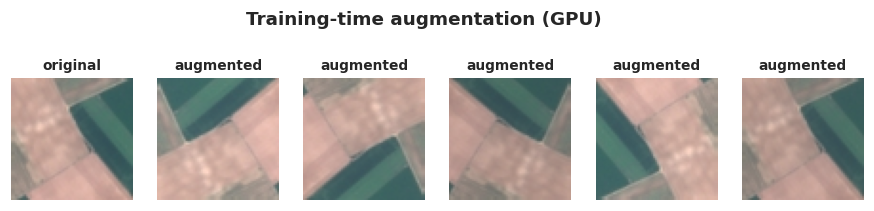

In [4]:
IM_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IM_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def gpu_augment(x):                                   # x: float [0,1], (B,3,H,W)
    B = x.shape[0]
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(2), x)
    k = torch.randint(0, 4, (B,), device=x.device)
    out = x.clone()
    for kk in (1, 2, 3):
        sel = k == kk
        if sel.any(): out[sel] = torch.rot90(x[sel], kk, (2, 3))
    b = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.3      # brightness +-15 %
    c = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.3      # contrast   +-15 %
    out = out * b
    m = out.mean(dim=(1, 2, 3), keepdim=True)
    return ((out - m) * c + m).clamp(0, 1)

def prep(xb_uint8, train):
    x = xb_uint8.float() / 255.0
    if train: x = gpu_augment(x)
    if IMG_SIZE != x.shape[-1]:
        x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (x - IM_MEAN) / IM_STD

# quick visual check of what the network actually sees
j = int(np.where(df["cls"] == "AnnualCrop")[0][3])
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
axes[0].imshow(X[j]); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(gpu_augment(Xall[j:j+1].float() / 255)[0].permute(1, 2, 0).cpu().numpy()); ax.set_title("augmented", fontsize=9)
for ax in axes: ax.axis("off")
fig.suptitle("Training-time augmentation (GPU)", fontweight="bold", y=1.08)
save(fig, "m3_01_augmentation")

# Part B — Model & training engine
One configurable function builds the network, trains it with **AdamW + One-Cycle LR schedule + early stopping**
(on validation macro-F1) and returns the best epoch's weights. Every experiment below calls the same function,
so comparisons are fair.

`cfg` fields: `arch`, `head` (`linear` or `bn_mlp`), `dropout`, `lr`, `wd`, `bs`, `bb_mult`
(backbone LR = `lr × bb_mult` — a lower rate protects the pretrained filters), `freeze_epochs`
(progressive unfreezing), `ls` (label smoothing).

In [5]:
def make_head(nf, kind, p):
    if kind == "linear":
        return nn.Sequential(nn.Dropout(p), nn.Linear(nf, NC))
    if kind == "bn_mlp":      # added layers: BatchNorm -> Dropout -> FC -> ReLU -> BatchNorm -> Dropout -> FC
        return nn.Sequential(nn.BatchNorm1d(nf), nn.Dropout(p), nn.Linear(nf, 256), nn.ReLU(inplace=True),
                             nn.BatchNorm1d(256), nn.Dropout(p), nn.Linear(256, NC))
    raise ValueError(kind)

def build_model(cfg):
    arch = cfg["arch"]
    if arch in ("resnet18", "resnet18_trunc"):
        m = resnet18(weights=ResNet18_Weights.DEFAULT if PRETRAINED else None)
        nf = m.fc.in_features
        if arch == "resnet18_trunc":          # REMOVE the last residual stage (layer4) -> 256-d features
            m.layer4 = nn.Identity(); nf = 256
        m.fc = make_head(nf, cfg["head"], cfg["dropout"]); m.head_name = "fc"
    elif arch == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if PRETRAINED else None)
        nf = m.classifier[1].in_features
        m.classifier = make_head(nf, cfg["head"], cfg["dropout"]); m.head_name = "classifier"
    else:
        raise ValueError(arch)
    return m.to(DEVICE)

autocast = lambda: torch.autocast(device_type="cuda" if DEVICE == "cuda" else "cpu",
                                  dtype=torch.float16, enabled=USE_AMP)

@torch.inference_mode()
def predict_proba(model, idx, tta=False, bs=512):
    # softmax probabilities for the given indices; tta = average of 4 flips/rotation views
    model.eval(); idx = T(idx); out = []
    for s in range(0, len(idx), bs):
        xb = prep(Xall[idx[s:s+bs]], train=False)
        with autocast():
            if tta:
                views = (xb, xb.flip(3), xb.flip(2), torch.rot90(xb, 1, (2, 3)))
                p = sum(model(v).float().softmax(1) for v in views) / len(views)
            else:
                p = model(xb).float().softmax(1)
        out.append(p.cpu())
    return torch.cat(out).numpy()

def score(model, idx):
    p = predict_proba(model, idx); y = yall[T(idx)].cpu().numpy()
    return dict(acc=accuracy_score(y, p.argmax(1)),
                f1=f1_score(y, p.argmax(1), average="macro"),
                loss=float(-np.log(p[np.arange(len(y)), y] + 1e-9).mean()))

def train_model(cfg, tr_idx, va_idx, epochs, patience=None, restore_best=True, seed=SEED, verbose=True):
    set_seed(seed)
    model = build_model(cfg)
    head = getattr(model, model.head_name)
    head_ids = {id(p) for p in head.parameters()}
    bb = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": bb, "lr": cfg["lr"] * cfg["bb_mult"]},
                             {"params": list(head.parameters()), "lr": cfg["lr"]}],
                            weight_decay=cfg["wd"])
    bs = cfg["bs"]; steps_per_epoch = max(1, len(tr_idx) // bs)       # full batches only (BatchNorm-safe)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[cfg["lr"] * cfg["bb_mult"], cfg["lr"]], total_steps=steps_per_epoch * epochs, pct_start=0.25)
    crit = nn.CrossEntropyLoss(label_smoothing=cfg.get("ls", 0.0))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    tr_t = T(tr_idx); hist, best, best_state, bad = [], -1, None, 0

    for ep in range(epochs):
        for p in bb: p.requires_grad_(ep >= cfg.get("freeze_epochs", 0))   # progressive unfreezing
        model.train(); t0 = time.time(); run_loss = run_ok = n = 0
        perm = tr_t[torch.randperm(len(tr_t), device=DEVICE)]
        for s in range(steps_per_epoch):
            b = perm[s * bs:(s + 1) * bs]
            xb, yb = prep(Xall[b], train=True), yall[b]
            with autocast():
                out = model(xb); loss = crit(out.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(b); run_ok += (out.argmax(1) == yb).sum().item(); n += len(b)
        v = score(model, va_idx)
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / n, train_acc=run_ok / n,
                         val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1"], sec=time.time() - t0))
        if verbose:
            print(f"  ep {ep+1:>2}/{epochs}  train loss {run_loss/n:.3f} acc {run_ok/n:.3f} | "
                  f"val loss {v['loss']:.3f} acc {v['acc']:.3f} F1 {v['f1']:.3f}  ({time.time()-t0:.0f}s)")
        if v["f1"] > best:
            best, bad = v["f1"], 0
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if patience and bad >= patience:
                if verbose: print(f"  early stop at epoch {ep+1} (best val F1 {best:.3f})")
                break
    if restore_best and best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

## B1. Baseline — default fine-tuning
Plain ResNet-18, linear head, no dropout, textbook settings (AdamW, lr 1e-3, batch 64). This is the **trained
reference model**: everything in Parts C–D has to beat it on the validation set.

In [6]:
BASE_CFG = dict(arch="resnet18", head="linear", dropout=0.0, lr=1e-3, wd=1e-4, bs=64,
                bb_mult=1.0, freeze_epochs=0, ls=0.0)
t0 = time.time()
base_model, base_hist = train_model(BASE_CFG, idx_tr, idx_va, EPOCHS_ABL)
base_val = score(base_model, idx_va)
print(f"\nBaseline fine-tuned ResNet-18 | val acc {base_val['acc']:.4f}  macro-F1 {base_val['f1']:.4f} "
      f"| {time.time()-t0:.0f}s")
print(f"Milestone 2 floor (frozen embeddings + LR): {M2_RESULTS['ResNet-18 frozen embeddings + LR']:.2f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


  ep  1/6  train loss 0.391 acc 0.879 | val loss 0.405 acc 0.877 F1 0.875  (15s)
  ep  2/6  train loss 0.257 acc 0.919 | val loss 0.199 acc 0.934 F1 0.932  (10s)
  ep  3/6  train loss 0.178 acc 0.943 | val loss 0.192 acc 0.935 F1 0.933  (10s)
  ep  4/6  train loss 0.115 acc 0.962 | val loss 0.077 acc 0.972 F1 0.972  (10s)
  ep  5/6  train loss 0.070 acc 0.977 | val loss 0.058 acc 0.978 F1 0.977  (10s)
  ep  6/6  train loss 0.051 acc 0.983 | val loss 0.049 acc 0.983 F1 0.982  (11s)

Baseline fine-tuned ResNet-18 | val acc 0.9827  macro-F1 0.9821 | 68s
Milestone 2 floor (frozen embeddings + LR): 0.92


# Part C — Hyperparameter tuning (Random Search)
**Why random, not grid?** Six hyper-parameters on a grid would need hundreds of runs. Random search covers
important dimensions (especially learning rate) far better for the same budget.
Each trial trains for a **short budget** (`EPOCHS_SEARCH`) and is ranked by validation macro-F1 — a cheap proxy
for how good the full run will be.

| Hyper-parameter | Range |
|---|---|
| learning rate | log-uniform 1e-4 … 3e-3 |
| batch size | 32, 64, 128 |
| dropout | 0, 0.2, 0.3, 0.5 |
| weight decay | log-uniform 1e-5 … 1e-2 |
| backbone LR multiplier | 0.1, 0.3, 1.0 |

In [7]:
def sample_cfg():
    return dict(arch="resnet18", head="linear",
                dropout=float(rng.choice([0.0, 0.2, 0.3, 0.5])),
                lr=float(10 ** rng.uniform(-4, math.log10(3e-3))),
                wd=float(10 ** rng.uniform(-5, -2)),
                bs=int(rng.choice([32, 64, 128])),
                bb_mult=float(rng.choice([0.1, 0.3, 1.0])),
                freeze_epochs=0, ls=0.0)

rows = []
for t in range(N_TRIALS):
    cfg = sample_cfg(); t0 = time.time()
    m, h = train_model(cfg, idx_tr, idx_va, EPOCHS_SEARCH, verbose=False)
    v = score(m, idx_va)
    rows.append({**cfg, "trial": t + 1, "val_f1": v["f1"], "val_acc": v["acc"], "sec": time.time() - t0})
    print(f"trial {t+1:>2}/{N_TRIALS}  lr {cfg['lr']:.1e}  bs {cfg['bs']:>3}  drop {cfg['dropout']:.1f}  "
          f"wd {cfg['wd']:.0e}  bb x{cfg['bb_mult']}  ->  val F1 {v['f1']:.4f}")
    del m;
    if DEVICE == "cuda": torch.cuda.empty_cache()

search = pd.DataFrame(rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
search.to_csv(TAB_DIR / "m3_random_search.csv", index=False)
BEST_HP = {k: search.loc[0, k] for k in ["dropout", "lr", "wd", "bs", "bb_mult"]}
BEST_HP["bs"] = int(BEST_HP["bs"])
print("\nBest hyper-parameters:", {k: (round(v, 6) if isinstance(v, float) else v) for k, v in BEST_HP.items()})
search.head(5).round(4)

trial  1/12  lr 4.4e-04  bs 128  drop 0.0  wd 4e-03  bb x0.1  ->  val F1 0.9724
trial  2/12  lr 1.4e-04  bs 128  drop 0.3  wd 8e-03  bb x1.0  ->  val F1 0.9799
trial  3/12  lr 1.5e-04  bs 128  drop 0.3  wd 2e-04  bb x0.3  ->  val F1 0.9693
trial  4/12  lr 2.3e-03  bs  64  drop 0.2  wd 9e-04  bb x1.0  ->  val F1 0.9757
trial  5/12  lr 2.2e-04  bs  64  drop 0.3  wd 5e-04  bb x1.0  ->  val F1 0.9817
trial  6/12  lr 1.7e-03  bs  32  drop 0.0  wd 8e-04  bb x1.0  ->  val F1 0.9762
trial  7/12  lr 2.7e-03  bs  64  drop 0.3  wd 5e-03  bb x1.0  ->  val F1 0.9732
trial  8/12  lr 1.9e-04  bs  64  drop 0.5  wd 3e-04  bb x0.1  ->  val F1 0.9617
trial  9/12  lr 1.0e-03  bs  32  drop 0.3  wd 2e-03  bb x0.3  ->  val F1 0.9821
trial 10/12  lr 3.0e-04  bs  32  drop 0.5  wd 1e-04  bb x0.3  ->  val F1 0.9790
trial 11/12  lr 1.6e-04  bs  32  drop 0.5  wd 3e-04  bb x0.1  ->  val F1 0.9625
trial 12/12  lr 9.8e-04  bs  32  drop 0.0  wd 2e-04  bb x1.0  ->  val F1 0.9775

Best hyper-parameters: {'dropout': np.f

,arch,head,dropout,lr,wd,bs,bb_mult,freeze_epochs,ls,trial,val_f1,val_acc,sec
0,resnet18,linear,0.3,0.0010,0.0017,32,0.3,0,0.0,9,0.9821,0.9825,55.0782
1,resnet18,linear,0.3,0.0002,0.0005,64,1.0,0,0.0,5,0.9817,0.9822,44.9673
2,resnet18,linear,0.3,0.0001,0.0085,128,1.0,0,0.0,2,0.9799,0.9805,40.6156
3,resnet18,linear,0.5,0.0003,0.0001,32,0.3,0,0.0,10,0.9790,0.9795,55.7107
4,resnet18,linear,0.0,0.0010,0.0002,32,1.0,0,0.0,12,0.9775,0.9780,55.1192


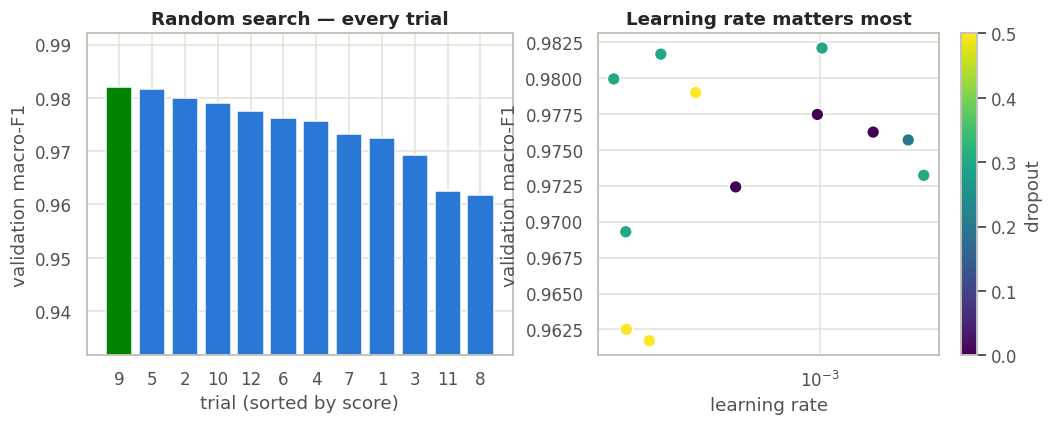

Correlation of each hyper-parameter with validation F1 (Spearman):


,rho
lr,0.17
wd,0.19
bs,-0.25
dropout,-0.19
bb_mult,0.56


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(len(search)), search["val_f1"], color=[GREEN if i == 0 else BLUE for i in range(len(search))])
ax[0].set_xticks(range(len(search))); ax[0].set_xticklabels(search["trial"])
ax[0].set_ylim(max(0, search["val_f1"].min() - 0.03), min(1, search["val_f1"].max() + 0.01))
ax[0].set_xlabel("trial (sorted by score)"); ax[0].set_ylabel("validation macro-F1"); ax[0].set_title("Random search — every trial")
sc = ax[1].scatter(search["lr"], search["val_f1"], c=search["dropout"], cmap="viridis", s=70, edgecolor="white")
ax[1].set_xscale("log"); ax[1].set_xlabel("learning rate"); ax[1].set_ylabel("validation macro-F1")
ax[1].set_title("Learning rate matters most"); plt.colorbar(sc, ax=ax[1], label="dropout")
save(fig, "m3_02_random_search")

print("Correlation of each hyper-parameter with validation F1 (Spearman):")
display(search[["lr", "wd", "bs", "dropout", "bb_mult"]].corrwith(search["val_f1"], method="spearman").round(2).to_frame("rho"))

# Part D — Model refinement (architecture & regularization)
Starting from the best hyper-parameters, we add one change at a time and keep it **only if validation F1 improves**:

| Step | Change | Why |
|---|---|---|
| D1 | Best hyper-parameters, linear head | Result of Part C |
| D2 | + dropout (if the search chose 0, we use 0.3) | Reduce overfitting |
| D3 | + **BatchNorm MLP head** (added layers) | More capacity on top of pretrained features, stable training |
| D4 | + **progressive unfreezing** (2 epochs head-only) | Don't wreck pretrained filters with random-head gradients |
| D5 | + label smoothing 0.1 | Softer targets, better calibration |
| D6 | **Remove** the last residual stage (`layer4`) | Smaller model — does 64×64 imagery need it? |
| D7 | Swap backbone: **EfficientNet-B0** | Different architecture family |

**Early stopping** (patience = `PATIENCE`) is active in every run.

In [9]:
def with_(cfg, **kw): return {**cfg, **kw}
steps = {}
steps["D1 best HPs (linear head)"]      = with_(BASE_CFG, **BEST_HP)
steps["D2 + dropout"]                   = with_(steps["D1 best HPs (linear head)"], dropout=BEST_HP["dropout"] or 0.3)
steps["D3 + BatchNorm MLP head"]        = with_(steps["D2 + dropout"], head="bn_mlp")
steps["D4 + progressive unfreezing"]    = with_(steps["D3 + BatchNorm MLP head"], freeze_epochs=2 if EPOCHS_ABL > 2 else 0)
steps["D5 + label smoothing"]           = with_(steps["D4 + progressive unfreezing"], ls=0.1)

abl, abl_models = [], {}
def run_step(name, cfg):
    t0 = time.time()
    m, h = train_model(cfg, idx_tr, idx_va, EPOCHS_ABL, patience=PATIENCE, verbose=False)
    v = score(m, idx_va); n_par = sum(p.numel() for p in m.parameters()) / 1e6
    abl.append(dict(step=name, val_acc=v["acc"], val_f1=v["f1"], best_epoch=int(h["val_f1"].idxmax()) + 1,
                    params_M=round(n_par, 2), sec=round(time.time() - t0)))
    abl_models[name] = (cfg, h)
    print(f"{name:<34} val F1 {v['f1']:.4f}  acc {v['acc']:.4f}  ({n_par:.1f}M params)")
    del m
    if DEVICE == "cuda": torch.cuda.empty_cache()

for name, cfg in steps.items(): run_step(name, cfg)

# keep the best of D1-D5 as the architecture for the two structural experiments
best_name = max(abl, key=lambda r: r["val_f1"])["step"]
best_cfg = abl_models[best_name][0]
print("\nBest so far:", best_name)
run_step("D6 remove layer4 (smaller ResNet)", with_(best_cfg, arch="resnet18_trunc"))
run_step("D7 EfficientNet-B0 backbone",       with_(best_cfg, arch="efficientnet_b0"))

ablation = pd.DataFrame(abl); ablation.to_csv(TAB_DIR / "m3_refinement_ablation.csv", index=False)
FINAL_NAME = ablation.loc[ablation["val_f1"].idxmax(), "step"]
FINAL_CFG = abl_models[FINAL_NAME][0]
print("\nSelected for final training ->", FINAL_NAME)
print(json.dumps(FINAL_CFG, indent=1))
ablation.round(4)

D1 best HPs (linear head)          val F1 0.9828  acc 0.9832  (11.2M params)
D2 + dropout                       val F1 0.9828  acc 0.9832  (11.2M params)
D3 + BatchNorm MLP head            val F1 0.9823  acc 0.9827  (11.3M params)
D4 + progressive unfreezing        val F1 0.9817  acc 0.9822  (11.3M params)
D5 + label smoothing               val F1 0.9837  acc 0.9842  (11.3M params)

Best so far: D5 + label smoothing
D6 remove layer4 (smaller ResNet)  val F1 0.9835  acc 0.9840  (2.9M params)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 122MB/s] 


D7 EfficientNet-B0 backbone        val F1 0.9860  acc 0.9867  (4.3M params)

Selected for final training -> D7 EfficientNet-B0 backbone
{
 "arch": "efficientnet_b0",
 "head": "bn_mlp",
 "dropout": 0.3,
 "lr": 0.0010208128465557418,
 "wd": 0.0017150882346504794,
 "bs": 32,
 "bb_mult": 0.3,
 "freeze_epochs": 2,
 "ls": 0.1
}


,step,val_acc,val_f1,best_epoch,params_M,sec
0,D1 best HPs (linear head),0.9832,0.9828,6,11.18,82
1,D2 + dropout,0.9832,0.9828,6,11.18,82
2,D3 + BatchNorm MLP head,0.9827,0.9823,6,11.31,84
3,D4 + progressive unfreezing,0.9822,0.9817,6,11.31,67
4,D5 + label smoothing,0.9842,0.9837,6,11.31,68
5,D6 remove layer4 (smaller ResNet),0.9840,0.9835,6,2.85,50
6,D7 EfficientNet-B0 backbone,0.9867,0.9860,6,4.34,151


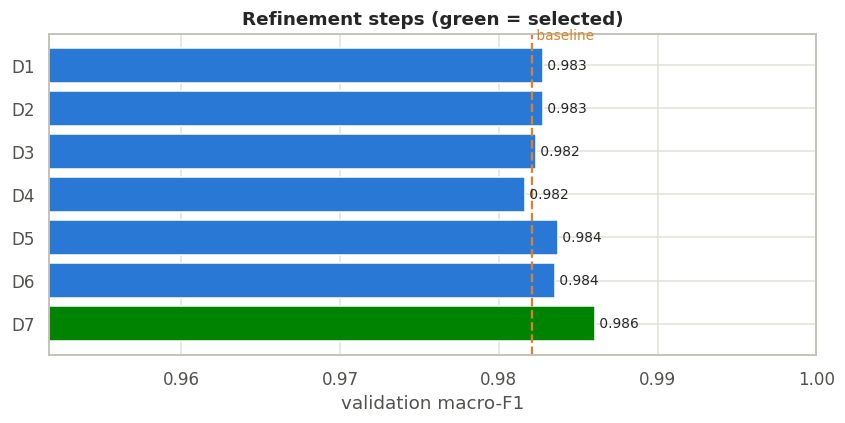

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ab = ablation.copy(); ab["short"] = ab["step"].str.split(" ", n=1).str[0]
cols = [GREEN if s == FINAL_NAME else BLUE for s in ab["step"]]
ax.barh(ab["short"][::-1], ab["val_f1"][::-1], color=cols[::-1])
for i, (v, s) in enumerate(zip(ab["val_f1"][::-1], ab["step"][::-1])):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ax.axvline(base_val["f1"], color=ORANGE, ls="--", lw=1.5); ax.text(base_val["f1"], len(ab) - 0.4, " baseline", color=ORANGE, fontsize=9)
ax.set_xlim(max(0, ab["val_f1"].min() - 0.03), min(1.0, ab["val_f1"].max() + 0.02))
ax.set_xlabel("validation macro-F1"); ax.set_title("Refinement steps (green = selected)")
save(fig, "m3_03_refinement")

## D8. Final training
The selected configuration trains for up to `EPOCHS_FINAL` epochs with early stopping. The curves show whether the
model overfits: validation loss rising while training loss keeps falling would trigger the early stop.

  ep  1/15  train loss 1.342 acc 0.651 | val loss 0.545 acc 0.859 F1 0.852  (12s)
  ep  2/15  train loss 0.969 acc 0.816 | val loss 0.437 acc 0.879 F1 0.874  (11s)
  ep  3/15  train loss 0.741 acc 0.919 | val loss 0.177 acc 0.974 F1 0.973  (28s)
  ep  4/15  train loss 0.639 acc 0.955 | val loss 0.158 acc 0.976 F1 0.975  (28s)
  ep  5/15  train loss 0.609 acc 0.964 | val loss 0.154 acc 0.981 F1 0.980  (28s)
  ep  6/15  train loss 0.595 acc 0.969 | val loss 0.151 acc 0.981 F1 0.980  (28s)
  ep  7/15  train loss 0.580 acc 0.974 | val loss 0.150 acc 0.985 F1 0.985  (28s)
  ep  8/15  train loss 0.566 acc 0.980 | val loss 0.155 acc 0.984 F1 0.984  (28s)
  ep  9/15  train loss 0.558 acc 0.983 | val loss 0.147 acc 0.984 F1 0.983  (28s)
  ep 10/15  train loss 0.547 acc 0.987 | val loss 0.152 acc 0.984 F1 0.984  (28s)
  ep 11/15  train loss 0.537 acc 0.991 | val loss 0.144 acc 0.987 F1 0.987  (28s)
  ep 12/15  train loss 0.535 acc 0.992 | val loss 0.146 acc 0.988 F1 0.988  (28s)
  ep 13/15  trai

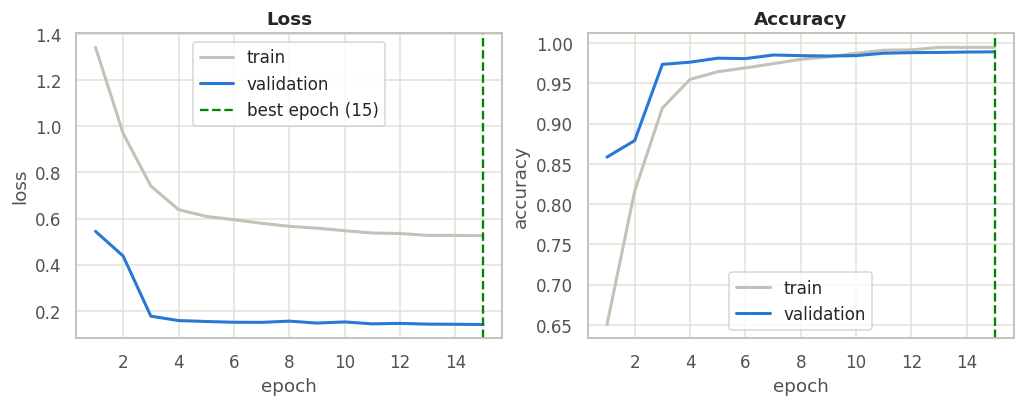

In [11]:
t0 = time.time()
final_model, final_hist = train_model(FINAL_CFG, idx_tr, idx_va, EPOCHS_FINAL, patience=PATIENCE, verbose=True)
final_val = score(final_model, idx_va)
final_hist.to_csv(TAB_DIR / "m3_final_training_history.csv", index=False)
best_ep = int(final_hist["val_f1"].idxmax()) + 1
print(f"\nFINAL model (validation) | acc {final_val['acc']:.4f}  macro-F1 {final_val['f1']:.4f} "
      f"| best epoch {best_ep}/{len(final_hist)} | {time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(final_hist["epoch"], final_hist["train_loss"], color=GRAY, lw=2, label="train")
ax[0].plot(final_hist["epoch"], final_hist["val_loss"], color=BLUE, lw=2, label="validation")
ax[0].axvline(best_ep, color=GREEN, ls="--", label=f"best epoch ({best_ep})"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(final_hist["epoch"], final_hist["train_acc"], color=GRAY, lw=2, label="train")
ax[1].plot(final_hist["epoch"], final_hist["val_acc"], color=BLUE, lw=2, label="validation")
ax[1].axvline(best_ep, color=GREEN, ls="--"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].set_title("Accuracy")
save(fig, "m3_04_training_curves")

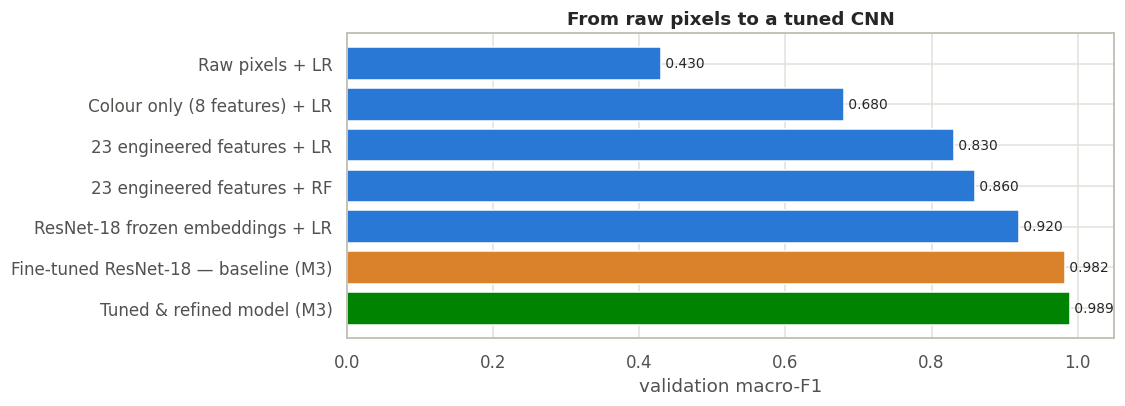

In [12]:
cmp = pd.DataFrame({"model": list(M2_RESULTS) + ["Fine-tuned ResNet-18 — baseline (M3)", "Tuned & refined model (M3)"],
                    "validation macro-F1": list(M2_RESULTS.values()) + [base_val["f1"], final_val["f1"]]})
cmp.to_csv(TAB_DIR / "m3_progress_vs_m2.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(cmp["model"][::-1], cmp["validation macro-F1"][::-1],
        color=[GREEN if "refined" in m else (ORANGE if "baseline" in m else BLUE) for m in cmp["model"][::-1]])
for i, v in enumerate(cmp["validation macro-F1"][::-1]): ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.05); ax.set_xlabel("validation macro-F1"); ax.set_title("From raw pixels to a tuned CNN")
save(fig, "m3_05_progress")

# Part E — Cross-validation (robustness)
A single validation split can be lucky. We re-train the **chosen configuration** on 5 different folds of
train + validation (the **test set stays untouched**) and report mean ± standard deviation. A small spread means the
result does not depend on one particular split.

In [13]:
trval = np.concatenate([idx_tr, idx_va]); y_trval = df["label"].values[trval]
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
for f, (a, b) in enumerate(skf.split(trval, y_trval), 1):
    m, h = train_model(FINAL_CFG, trval[a], trval[b], EPOCHS_CV, restore_best=False, seed=SEED + f, verbose=False)
    v = score(m, trval[b]); cv_rows.append(dict(fold=f, acc=v["acc"], macro_f1=v["f1"]))
    print(f"fold {f}/{N_FOLDS}  acc {v['acc']:.4f}  macro-F1 {v['f1']:.4f}")
    del m
    if DEVICE == "cuda": torch.cuda.empty_cache()
cv = pd.DataFrame(cv_rows); cv.to_csv(TAB_DIR / "m3_cross_validation.csv", index=False)
print(f"\n{N_FOLDS}-fold CV: accuracy {cv['acc'].mean():.4f} ± {cv['acc'].std():.4f} | "
      f"macro-F1 {cv['macro_f1'].mean():.4f} ± {cv['macro_f1'].std():.4f}")
cv.round(4)

fold 1/5  acc 0.9861  macro-F1 0.9856
fold 2/5  acc 0.9889  macro-F1 0.9885
fold 3/5  acc 0.9856  macro-F1 0.9852
fold 4/5  acc 0.9861  macro-F1 0.9853
fold 5/5  acc 0.9852  macro-F1 0.9847

5-fold CV: accuracy 0.9864 ± 0.0015 | macro-F1 0.9858 ± 0.0015


,fold,acc,macro_f1
0,1,0.9861,0.9856
1,2,0.9889,0.9885
2,3,0.9856,0.9852
3,4,0.9861,0.9853
4,5,0.9852,0.9847


# Part F — Final evaluation on the unseen test set
> **The test set is opened here, once.** No hyper-parameter, architecture or epoch choice was made with it,
> and nothing is changed after seeing these numbers. The un-tuned baseline is scored in the same pass purely to
> *quantify the improvement*.

Booklet categories (EuroSAT has no desert class, so we evaluate its 10 classes and also report the booklet's groups):

| Booklet category | EuroSAT classes |
|---|---|
| Agriculture | AnnualCrop, PermanentCrop, Pasture, HerbaceousVegetation |
| Water | River, SeaLake |
| Urban | Residential, Industrial |
| Roads | Highway |
| Trees | Forest |

In [14]:
assert "TEST_OPENED" not in globals(), "Test set was already opened - do not re-run this cell after tuning."
TEST_OPENED = True

y_te = df["label"].values[idx_te]
p_final = predict_proba(final_model, idx_te)                  # primary result (no TTA)
p_tta   = predict_proba(final_model, idx_te, tta=True)        # secondary: flip/rotate test-time augmentation
p_base  = predict_proba(base_model, idx_te)
pred = p_final.argmax(1)

res = pd.DataFrame({
    "model": ["Baseline fine-tuned ResNet-18", "Tuned & refined model", "Tuned & refined + TTA"],
    "test accuracy": [accuracy_score(y_te, p.argmax(1)) for p in (p_base, p_final, p_tta)],
    "test macro-F1": [f1_score(y_te, p.argmax(1), average="macro") for p in (p_base, p_final, p_tta)]})
res.to_csv(TAB_DIR / "m3_test_summary.csv", index=False)
display(res.round(4))

# 95 % bootstrap confidence interval on the primary accuracy
boots = [accuracy_score(y_te[i], pred[i]) for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(1000))]
lo, hi = np.percentile(boots, [2.5, 97.5])
TEST_ACC, TEST_F1 = accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro")
print(f"TEST accuracy {TEST_ACC:.4f}  (95% CI {lo:.4f} – {hi:.4f}) | macro-F1 {TEST_F1:.4f} | n = {len(y_te):,}")

,model,test accuracy,test macro-F1
0,Baseline fine-tuned ResNet-18,0.9854,0.9847
1,Tuned & refined model,0.9923,0.9921
2,Tuned & refined + TTA,0.9926,0.9924


TEST accuracy 0.9923  (95% CI 0.9894 – 0.9948) | macro-F1 0.9921 | n = 4,050


In [15]:
# Per-class report (per-class accuracy == recall)
pr, rc, f1c, sup = precision_recall_fscore_support(y_te, pred, labels=range(NC), zero_division=0)
percls = pd.DataFrame({"class": CLASSES, "accuracy (recall)": rc, "precision": pr, "F1": f1c, "support": sup}).set_index("class")
percls.to_csv(TAB_DIR / "m3_test_per_class.csv")
display(percls.round(3))

BOOKLET = {"Agriculture": ["AnnualCrop", "PermanentCrop", "Pasture", "HerbaceousVegetation"],
           "Water": ["River", "SeaLake"], "Urban": ["Residential", "Industrial"],
           "Roads": ["Highway"], "Trees": ["Forest"]}
cls_arr = np.array(CLASSES)
grp_rows = []
for g, members in BOOKLET.items():
    mask = np.isin(cls_arr[y_te], members)
    grp_rows.append(dict(category=g, images=int(mask.sum()),
                         exact_class_accuracy=float((pred[mask] == y_te[mask]).mean()),
                         category_accuracy=float(np.isin(cls_arr[pred[mask]], members).mean())))
groups = pd.DataFrame(grp_rows).set_index("category"); groups.to_csv(TAB_DIR / "m3_test_booklet_groups.csv")
print("Booklet categories — exact_class_accuracy: right class | category_accuracy: right category (e.g. any farmland class):")
display(groups.round(3))

,accuracy (recall),precision,F1,support
class,,,,
AnnualCrop,0.984,0.989,0.987,450
Forest,0.993,1.000,0.997,450
HerbaceousVegetation,0.993,0.982,0.988,450
Highway,0.995,0.995,0.995,375
Industrial,0.995,0.989,0.992,375
Pasture,0.983,0.987,0.985,300
PermanentCrop,0.987,0.987,0.987,375
Residential,0.993,1.000,0.997,450
River,1.000,0.997,0.999,375


Booklet categories — exact_class_accuracy: right class | category_accuracy: right category (e.g. any farmland class):


,images,exact_class_accuracy,category_accuracy
category,,,
Agriculture,1575,0.987,0.999
Water,825,0.999,0.999
Urban,825,0.994,0.998
Roads,375,0.995,0.995
Trees,450,0.993,0.993


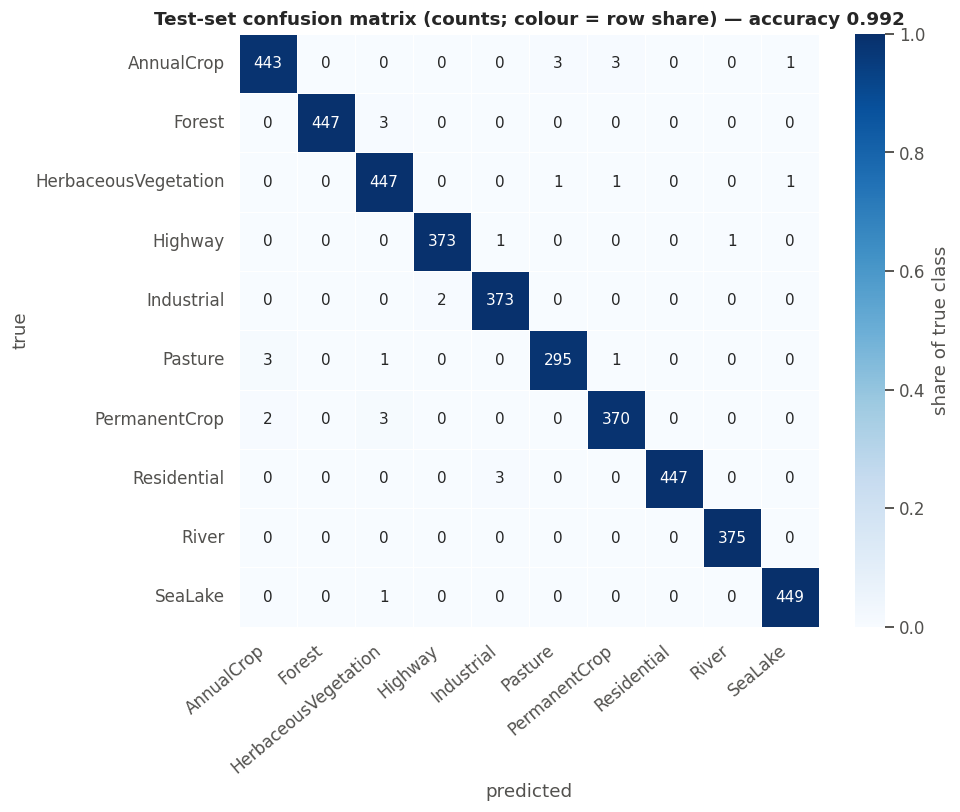

Most frequent mistakes:


,true,predicted,images,share of true class
0,AnnualCrop,Pasture,3,0.007
1,AnnualCrop,PermanentCrop,3,0.007
3,Forest,HerbaceousVegetation,3,0.007
14,PermanentCrop,HerbaceousVegetation,3,0.008
10,Pasture,AnnualCrop,3,0.010
15,Residential,Industrial,3,0.007
9,Industrial,Highway,2,0.005
13,PermanentCrop,AnnualCrop,2,0.005


In [16]:
cm = confusion_matrix(y_te, pred, labels=range(NC)); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES,
            cbar_kws={"label": "share of true class"}, linewidths=.5, linecolor="white", ax=ax)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
ax.set_title(f"Test-set confusion matrix (counts; colour = row share) — accuracy {TEST_ACC:.3f}")
save(fig, "m3_06_test_confusion")

off = [(CLASSES[i], CLASSES[j], int(cm[i, j]), cmn[i, j]) for i in range(NC) for j in range(NC) if i != j and cm[i, j] > 0]
top = pd.DataFrame(off, columns=["true", "predicted", "images", "share of true class"]).sort_values("images", ascending=False).head(8)
top.to_csv(TAB_DIR / "m3_test_top_confusions.csv", index=False)
print("Most frequent mistakes:"); display(top.round(3))

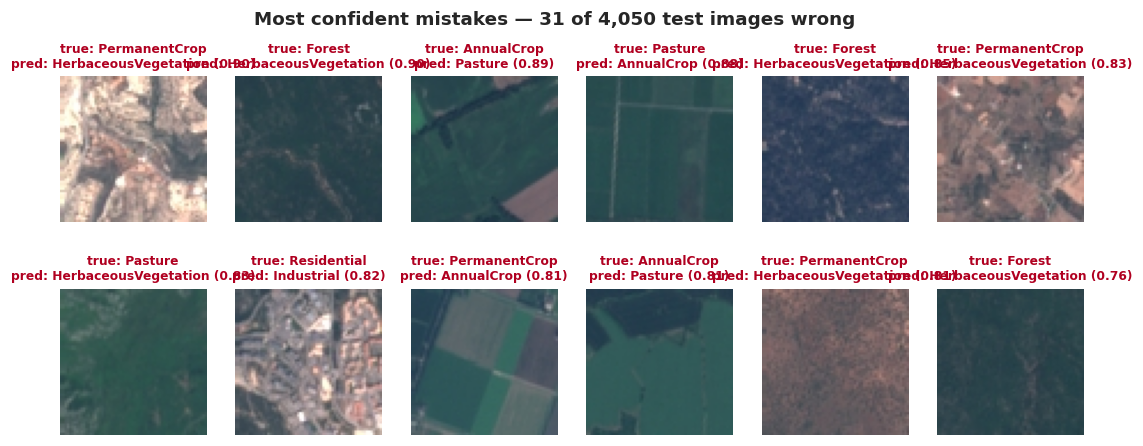

In [17]:
wrong = np.where(pred != y_te)[0]
conf = p_final.max(1)
show = wrong[np.argsort(-conf[wrong])][:12]                   # the most confidently wrong predictions
if len(show):
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
    for ax, k in zip(axes.ravel(), show):
        ax.imshow(X[idx_te[k]]); ax.axis("off")
        ax.set_title(f"true: {CLASSES[y_te[k]]}\npred: {CLASSES[pred[k]]} ({conf[k]:.2f})", fontsize=8, color="#b00020")
    for ax in axes.ravel()[len(show):]: ax.axis("off")
    fig.suptitle(f"Most confident mistakes — {len(wrong)} of {len(y_te):,} test images wrong", fontweight="bold")
    save(fig, "m3_07_test_errors")
else:
    print("No test errors.")

# Deliverables & summary
1. **Optimized, fine-tuned model** → `outputs/models/eurosat_resnet_final.pt` (+ `model_config.json`)
2. **Detailed evaluation report** → the test-set tables and figures above; every table is also in `outputs/tables/`,
   every figure in `outputs/figures/`.

In [18]:
torch.save(final_model.state_dict(), MOD_DIR / "eurosat_resnet_final.pt")
json.dump({"config": FINAL_CFG, "classes": CLASSES, "img_size": IMG_SIZE,
           "normalize_mean": IM_MEAN.flatten().tolist(), "normalize_std": IM_STD.flatten().tolist(),
           "test_accuracy": TEST_ACC, "test_macro_f1": TEST_F1},
          open(MOD_DIR / "model_config.json", "w"), indent=1)

n_par = sum(p.numel() for p in final_model.parameters()) / 1e6
print("=" * 66)
print(f"Baseline fine-tuned ResNet-18   val F1 {base_val['f1']:.4f}   test acc {res.loc[0, 'test accuracy']:.4f}")
print(f"Tuned & refined model           val F1 {final_val['f1']:.4f}   test acc {TEST_ACC:.4f}  (95% CI {lo:.3f}–{hi:.3f})")
print(f"Milestone 2 frozen-feature floor: 0.92 val F1")
print(f"{N_FOLDS}-fold CV macro-F1: {cv['macro_f1'].mean():.4f} ± {cv['macro_f1'].std():.4f}")
print(f"Selected architecture: {FINAL_NAME}  ({n_par:.1f}M parameters)")
print(f"Weakest class on test: {percls['accuracy (recall)'].idxmin()} ({percls['accuracy (recall)'].min():.3f})")
print("=" * 66)
print("Saved:", *sorted(p.name for p in MOD_DIR.iterdir()), sep="\n  ")

Baseline fine-tuned ResNet-18   val F1 0.9821   test acc 0.9854
Tuned & refined model           val F1 0.9888   test acc 0.9923  (95% CI 0.989–0.995)
Milestone 2 frozen-feature floor: 0.92 val F1
5-fold CV macro-F1: 0.9858 ± 0.0015
Selected architecture: D7 EfficientNet-B0 backbone  (4.3M parameters)
Weakest class on test: Pasture (0.983)
Saved:
  eurosat_resnet_final.pt
  model_config.json


In [19]:
   !zip -r outputs_m3.zip outputs
   from google.colab import files
   files.download("outputs_m3.zip")

  adding: outputs/ (stored 0%)
  adding: outputs/tables/ (stored 0%)
  adding: outputs/tables/m3_test_summary.csv (deflated 32%)
  adding: outputs/tables/m3_final_training_history.csv (deflated 54%)
  adding: outputs/tables/m3_refinement_ablation.csv (deflated 42%)
  adding: outputs/tables/m3_random_search.csv (deflated 57%)
  adding: outputs/tables/m3_test_top_confusions.csv (deflated 58%)
  adding: outputs/tables/m3_progress_vs_m2.csv (deflated 33%)
  adding: outputs/tables/m3_test_per_class.csv (deflated 55%)
  adding: outputs/tables/m3_test_booklet_groups.csv (deflated 54%)
  adding: outputs/tables/m3_cross_validation.csv (deflated 47%)
  adding: outputs/models/ (stored 0%)
  adding: outputs/models/model_config.json (deflated 42%)
  adding: outputs/models/eurosat_resnet_final.pt (deflated 8%)
  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/m3_01_augmentation.png (deflated 1%)
  adding: outputs/figures/m3_06_test_confusion.png (deflated 10%)
  adding: outputs/figure

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>